In [1]:
import re, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

In [2]:
docs = [
    "the cat sat on the mat",
    "the dog sat on the log",
    "the cat and the dog are friends",
    "machine learning is fun",
]

In [3]:
tok = lambda t: re.findall(r"(?u)\b\w\w+\b", t.lower())
vocab = sorted({w for d in docs for w in tok(d)})
N = len(docs)

tf = np.array([[tok(d).count(w) for w in vocab] for d in docs], dtype=float)
df_ = (tf > 0).sum(axis=0)
idf = np.log((1 + N) / (1 + df_)) + 1
tfidf = tf * idf
tfidf = tfidf / np.linalg.norm(tfidf, axis=1, keepdims=True)      # L2 normalisation

idx = [f"D{i+1}" for i in range(N)]
df_tfidf = pd.DataFrame(tfidf.round(3), columns=vocab, index=idx)
df_tfidf

,and,are,cat,dog,friends,fun,is,learning,log,machine,mat,on,sat,the
D1,0.000,0.000,0.372,0.000,0.000,0.0,0.0,0.0,0.000,0.0,0.472,0.372,0.372,0.602
D2,0.000,0.000,0.000,0.372,0.000,0.0,0.0,0.0,0.472,0.0,0.000,0.372,0.372,0.602
D3,0.413,0.413,0.325,0.325,0.413,0.0,0.0,0.0,0.000,0.0,0.000,0.000,0.000,0.527
D4,0.000,0.000,0.000,0.000,0.000,0.5,0.5,0.5,0.000,0.5,0.000,0.000,0.000,0.000


In [4]:
sk = TfidfVectorizer().fit(docs)
sk_mat = sk.transform(docs).toarray()
print("Manual == sklearn TF-IDF :", np.allclose(tfidf, sk_mat))
print("\nIDF values:")
print(pd.Series(idf, index=vocab).round(3).sort_values())

Manual == sklearn TF-IDF : True

IDF values:
the         1.223
dog         1.511
on          1.511
cat         1.511
sat         1.511
friends     1.916
are         1.916
and         1.916
learning    1.916
is          1.916
fun         1.916
log         1.916
mat         1.916
machine     1.916
dtype: float64


,BoW count,TF-IDF
and,0,0.000
are,0,0.000
cat,1,0.372
dog,0,0.000
friends,0,0.000
fun,0,0.000
is,0,0.000
learning,0,0.000
log,0,0.000
machine,0,0.000


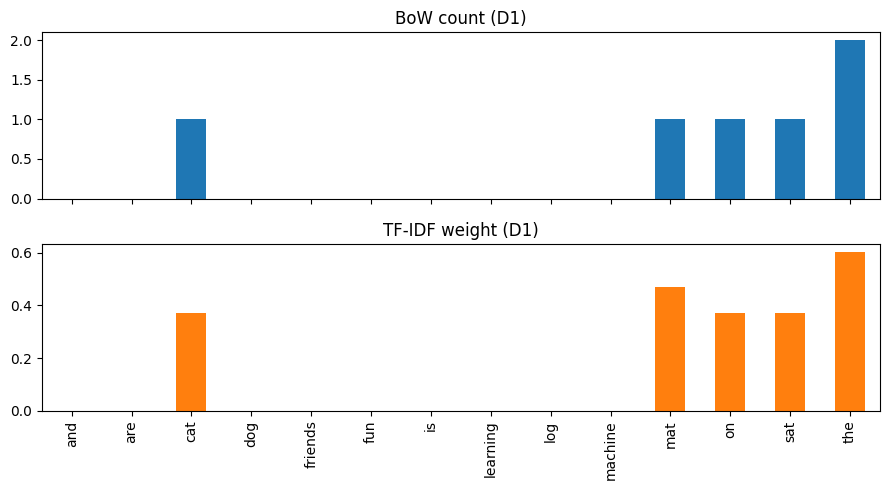

In [5]:
bow = CountVectorizer().fit_transform(docs).toarray()
cmp = pd.DataFrame({"BoW count": bow[0], "TF-IDF": tfidf[0].round(3)}, index=vocab)
display(cmp)

cmp.plot(kind="bar", subplots=True, figsize=(9, 5), legend=False, title=["BoW count (D1)", "TF-IDF weight (D1)"])
plt.tight_layout(); plt.show()